<a href="https://colab.research.google.com/github/manikanta-eng/python-project/blob/main/PCB_COMPONENT_DETECTION.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


========== GPU INFORMATION ==========
PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4

========== DOWNLOADING DATASET ==========
Using Colab cache for faster access to the 'pcb-component-detection-consolidated-dataset' dataset.
Dataset location: /kaggle/input/pcb-component-detection-consolidated-dataset

========== SEARCHING DATASET CONFIGURATION ==========
Selected YAML: /kaggle/input/pcb-component-detection-consolidated-dataset/components_data_uncropped/data.yaml
Train directory: /kaggle/input/pcb-component-detection-consolidated-dataset/components_data_uncropped/train/images
Validation directory: /kaggle/input/pcb-component-detection-consolidated-dataset/components_data_uncropped/valid/images

Classes: {0: 'battery', 1: 'button', 2: 'buzzer', 3: 'capacitor', 4: 'clock', 5: 'connector', 6: 'diode', 7: 'display', 8: 'fuse', 9: 'heatsink', 10: 'ic', 11: 'inductor', 12: 'led', 13: 'pads', 14: 'pins', 15: 'potentiometer', 16: 'relay', 17: 'resistor', 18: 'switch', 19: 'transduc

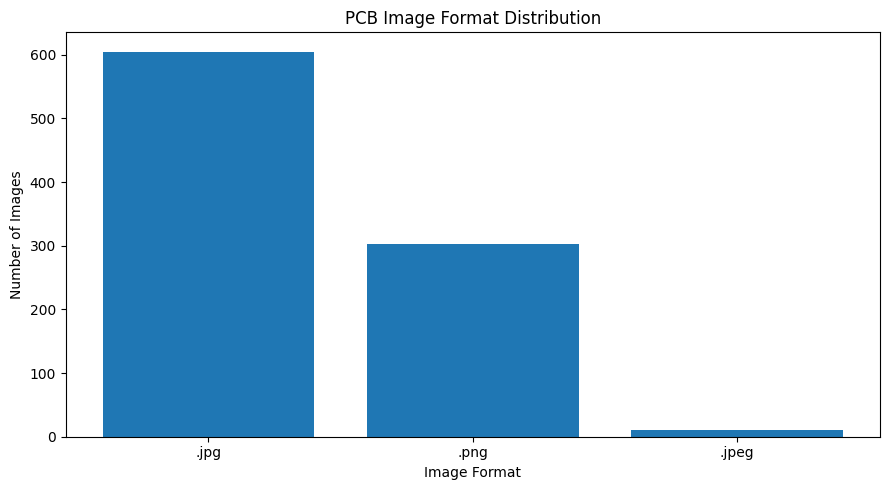

Analyzing annotations:   0%|          | 0/917 [00:00<?, ?it/s]


========== CLASS DISTRIBUTION ==========


,Class ID,Class,Object Count
0,0,battery,54
1,1,button,85
2,2,buzzer,60
3,3,capacitor,10631
4,4,clock,122
5,5,connector,1311
6,6,diode,746
7,7,display,86
8,8,fuse,153
9,9,heatsink,4


Valid annotations: 29669
Invalid annotations: 0


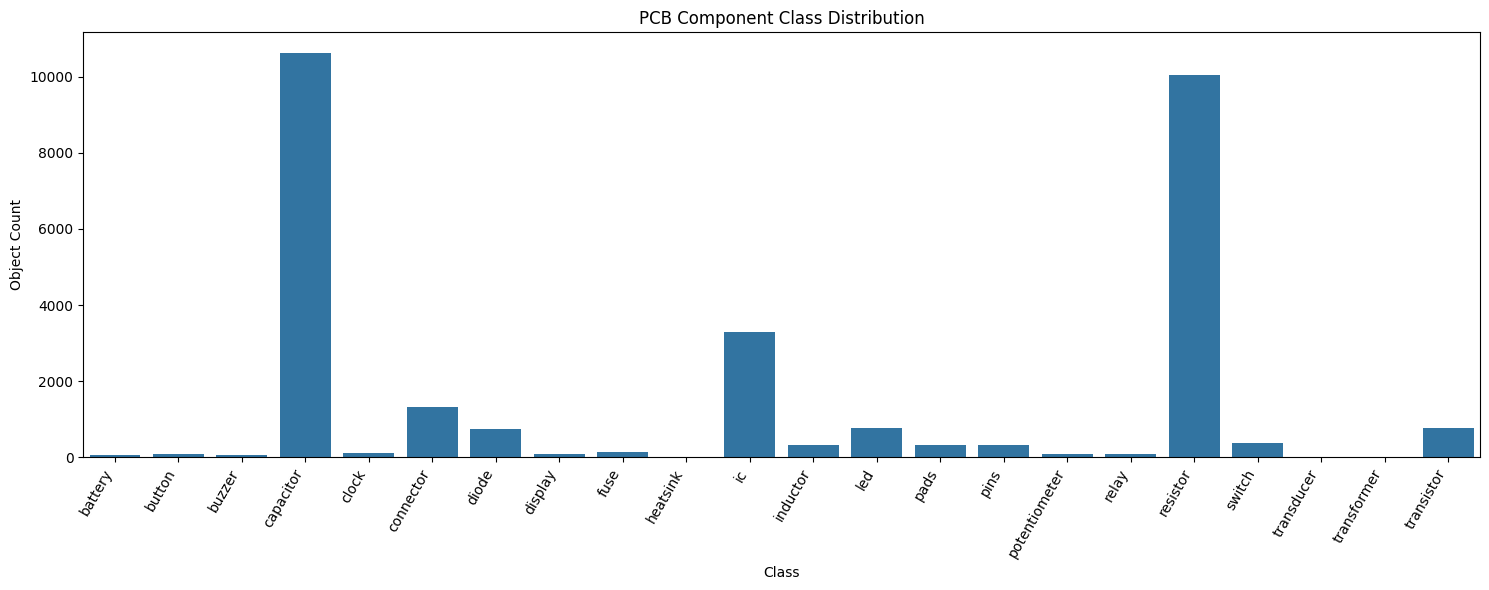


========== IMAGE RESOLUTION ANALYSIS ==========


Checking image sizes:   0%|          | 0/917 [00:00<?, ?it/s]

,Resolution,Count
0,"(1024, 1024)",192
1,"(8256, 5504)",50
2,"(1000, 1000)",17
3,"(4112, 3008)",15
4,"(800, 800)",8
5,"(500, 500)",8
6,"(1001, 1001)",6
7,"(1400, 1400)",6
8,"(225, 225)",5
9,"(1500, 1500)",4


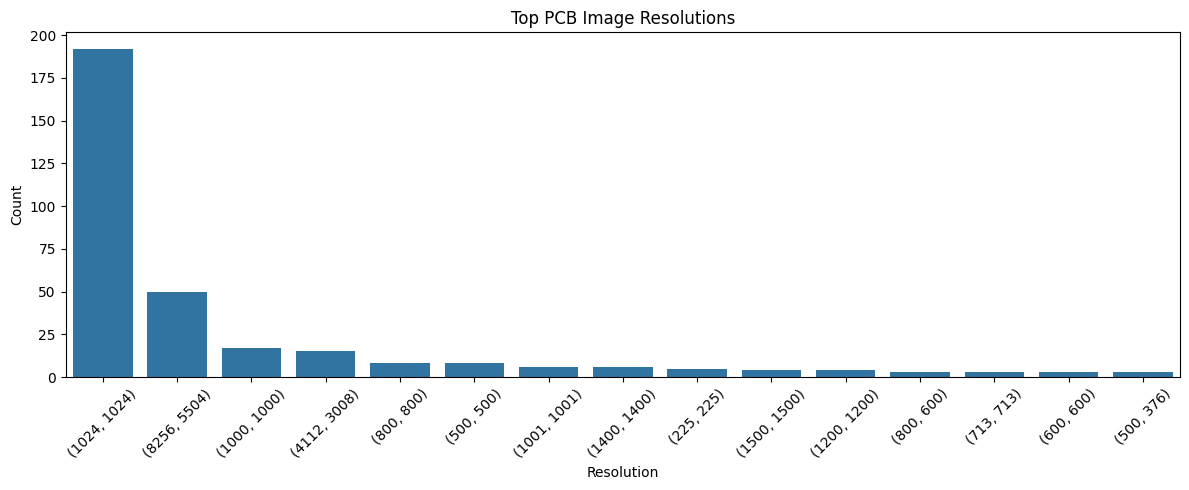


========== DUPLICATE IMAGE ANALYSIS ==========


Checking duplicates:   0%|          | 0/917 [00:00<?, ?it/s]

Unique image hashes: 914
Duplicate groups: 3
Extra duplicate images: 3

========== SAMPLE PCB IMAGES ==========


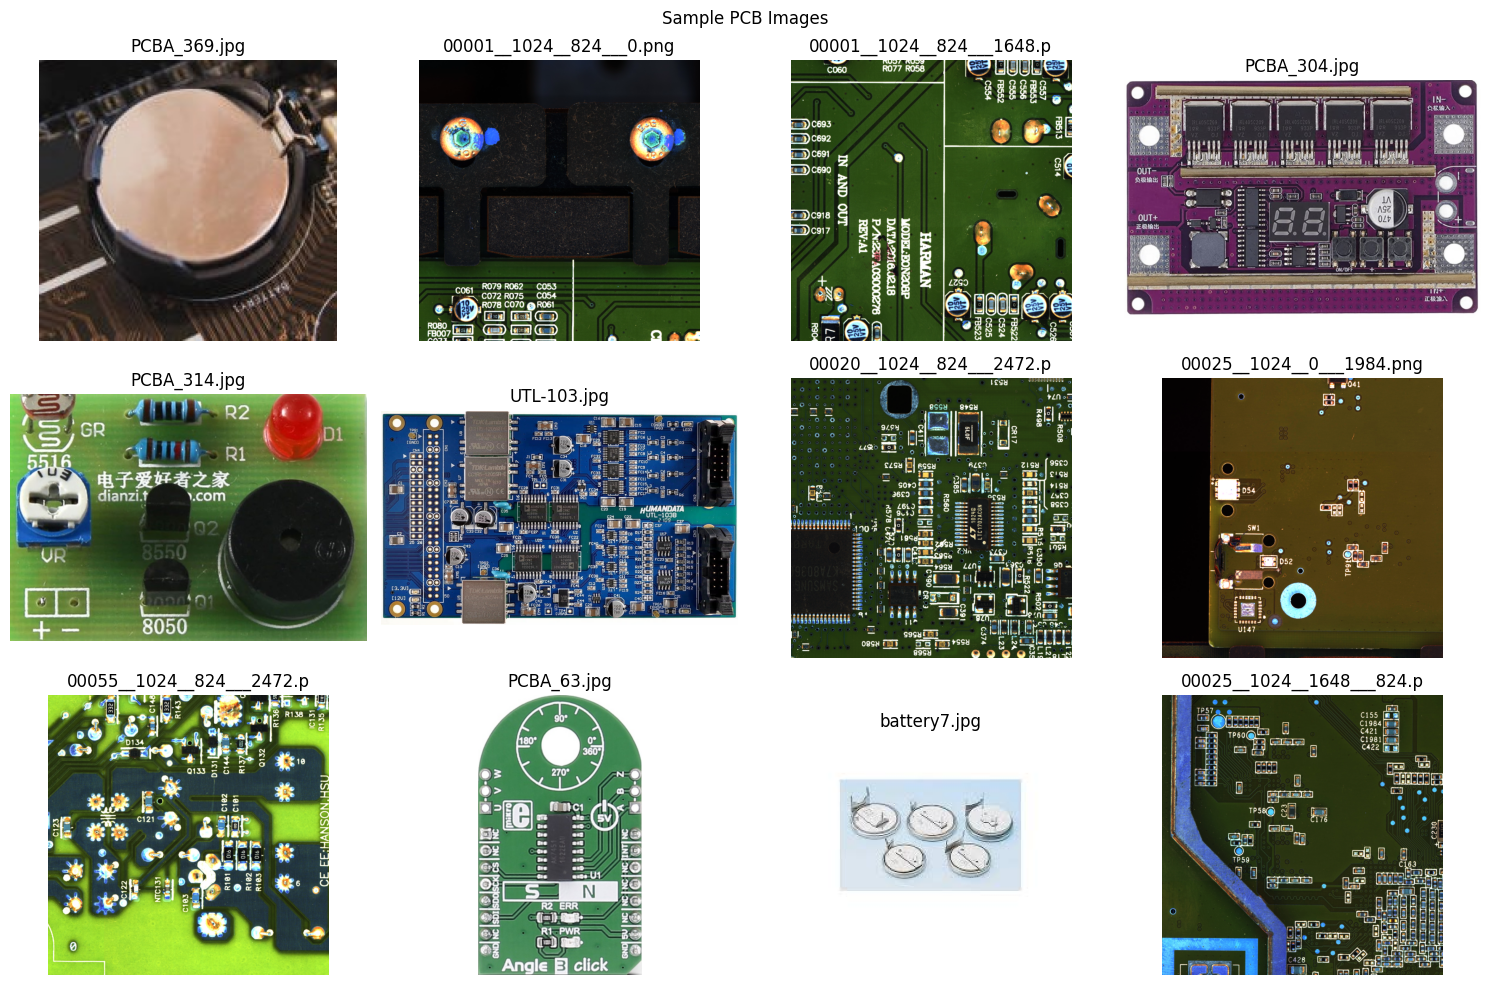


========== TRAIN / VALIDATION DATA ==========
Training images: 670
Validation images: 125
Train labels: /kaggle/input/pcb-component-detection-consolidated-dataset/components_data_uncropped/train/labels
Validation labels: /kaggle/input/pcb-component-detection-consolidated-dataset/components_data_uncropped/valid/labels
Training label files: 670
Validation label files: 125

========== STARTING SEVEN MODEL TRAINING ==========


MODEL 1/7: yolov8n.pt
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/pcb_fixed_data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dl

,Model,Precision,Recall,mAP50,mAP50-95
0,yolov8n.pt,0.622366,0.391382,0.402200,0.261830
1,yolov8s.pt,0.591637,0.424224,0.471264,0.309783
2,yolov8m.pt,0.654121,0.441377,0.483679,0.310193
3,yolov8l.pt,0.509304,0.490988,0.459880,0.295064
4,yolov8x.pt,0.637732,0.466327,0.474452,0.298170
5,yolo11n.pt,0.590873,0.365694,0.403836,0.254156
6,yolo11s.pt,0.525700,0.424186,0.452120,0.286062


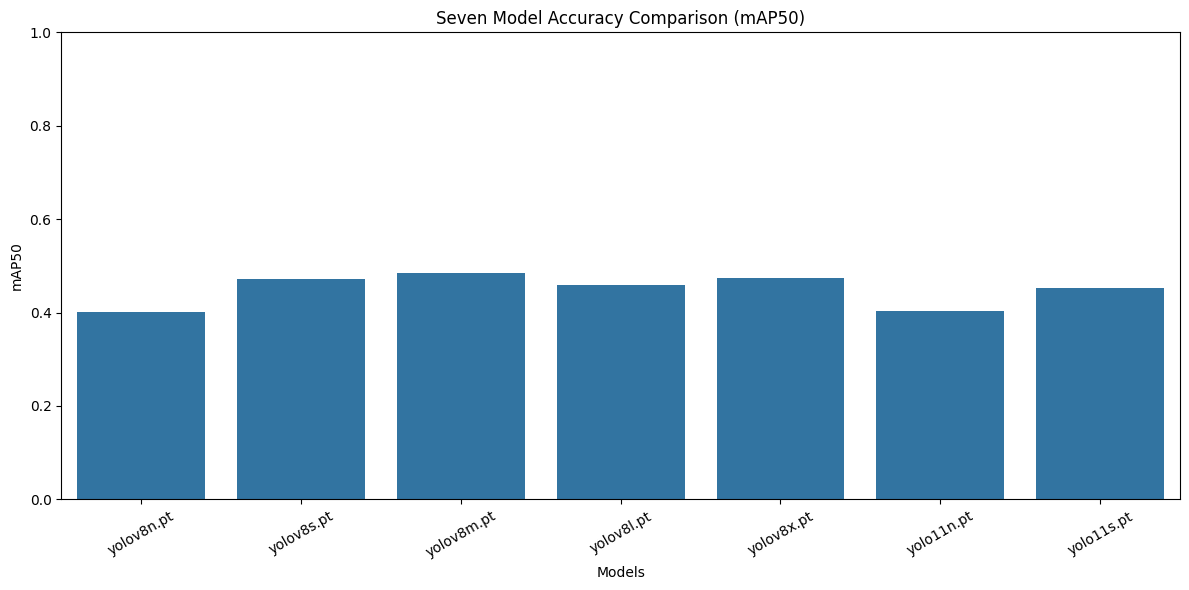

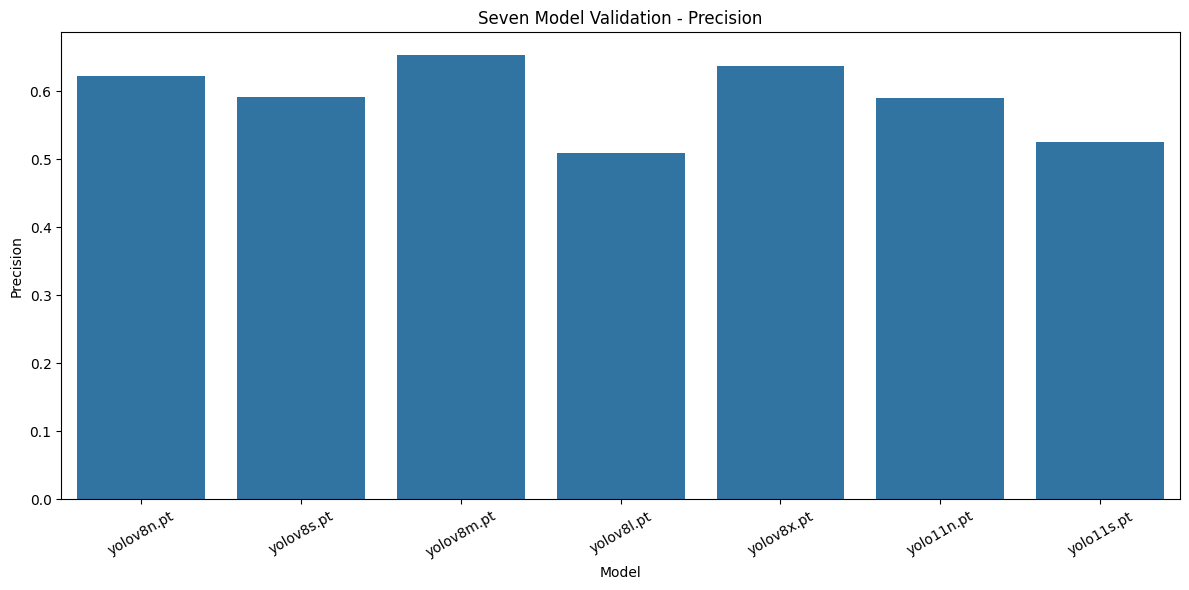

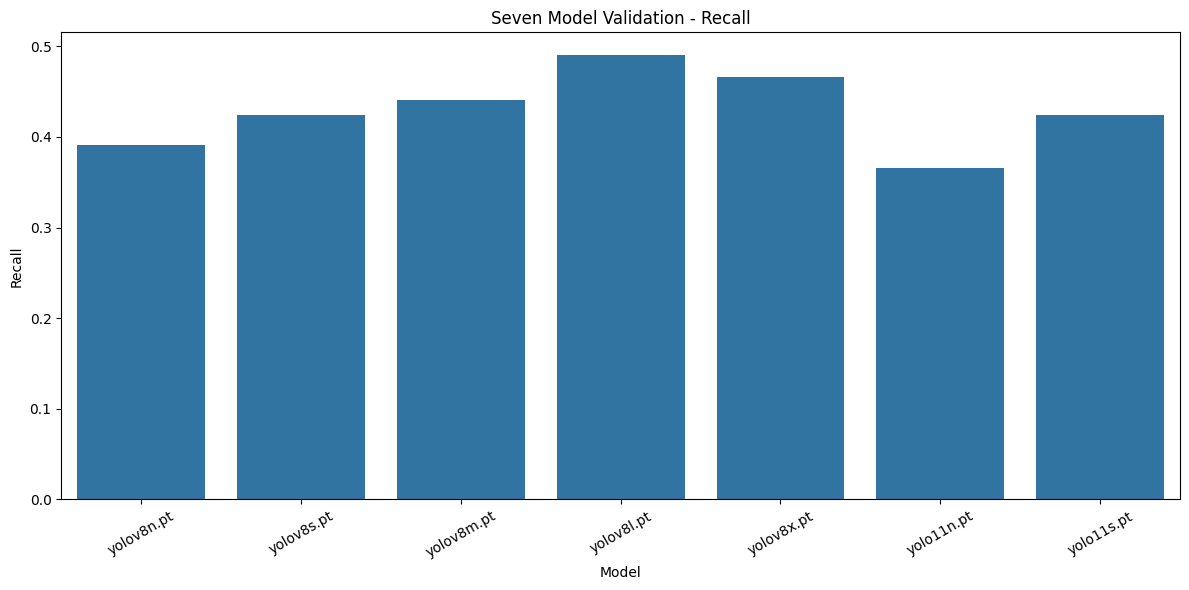

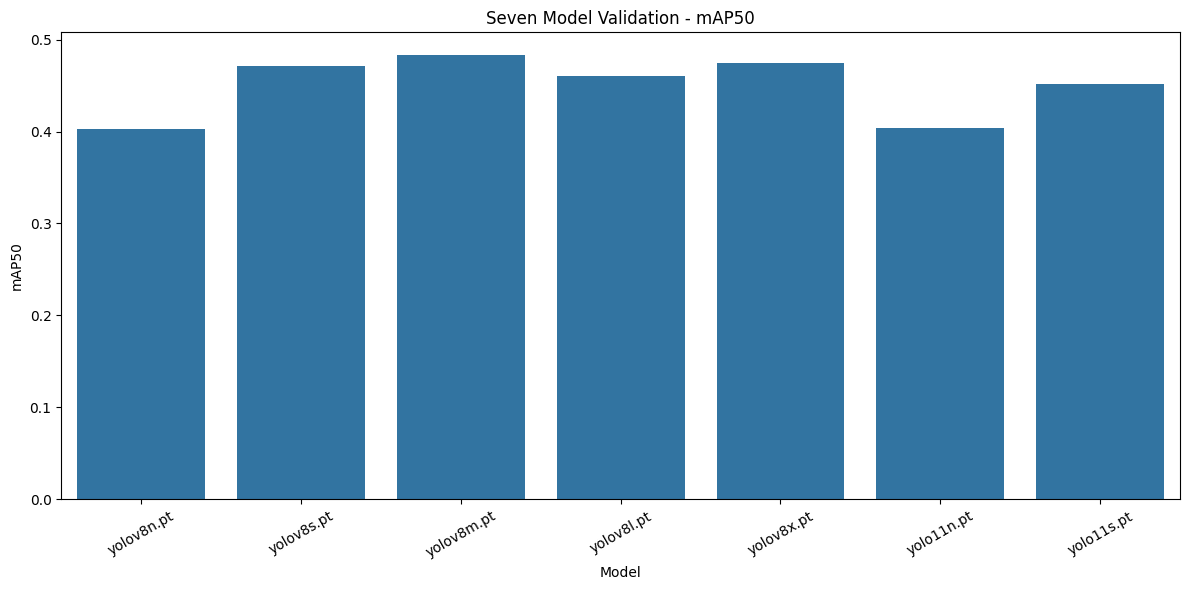

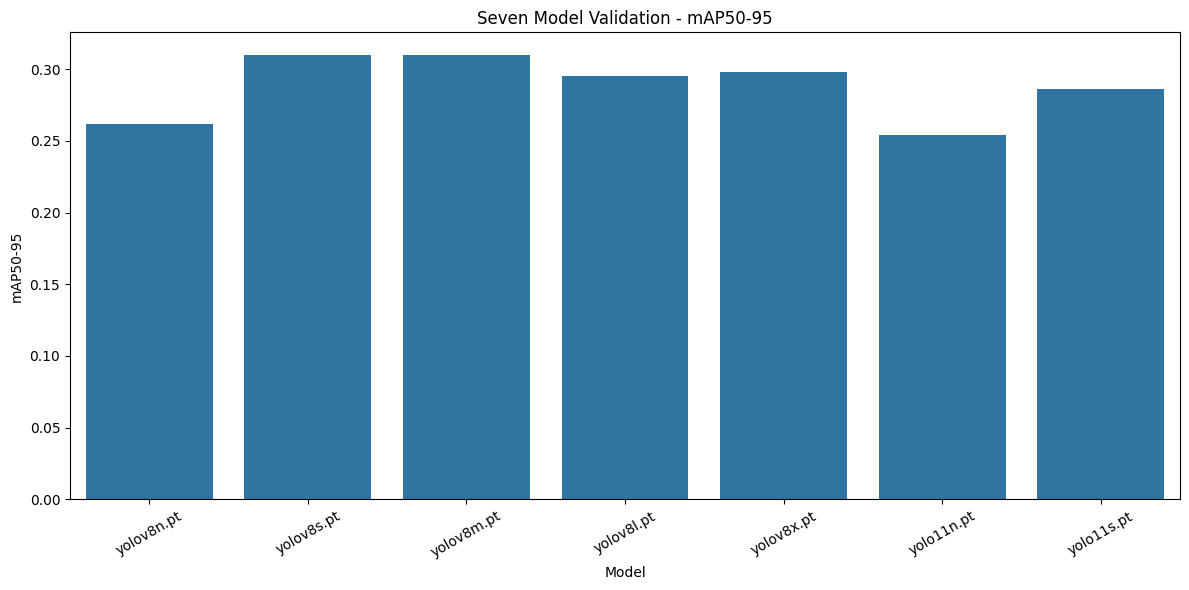

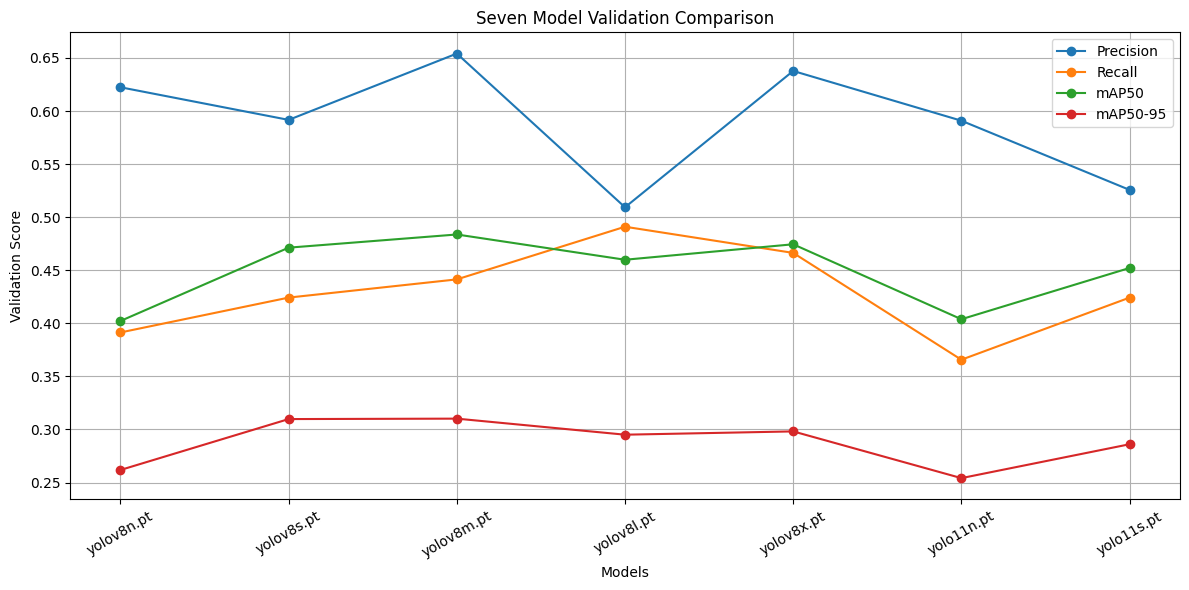

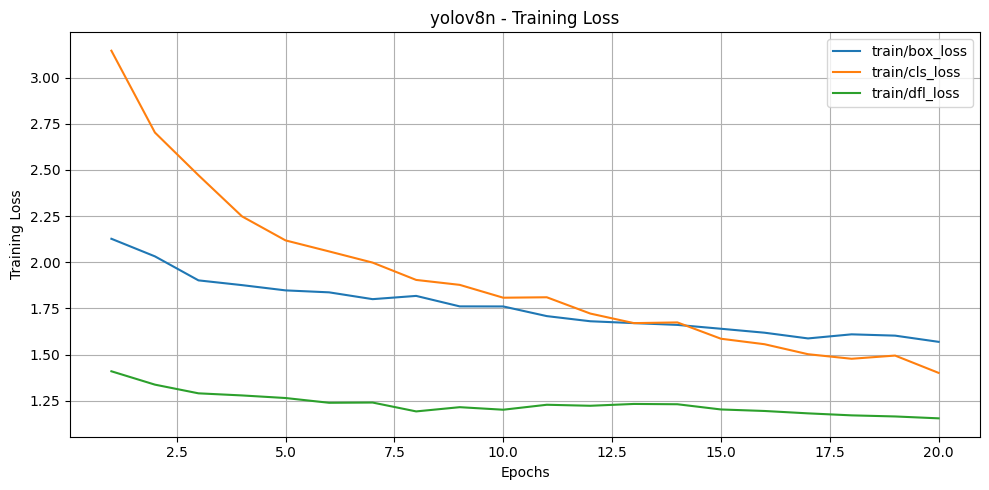

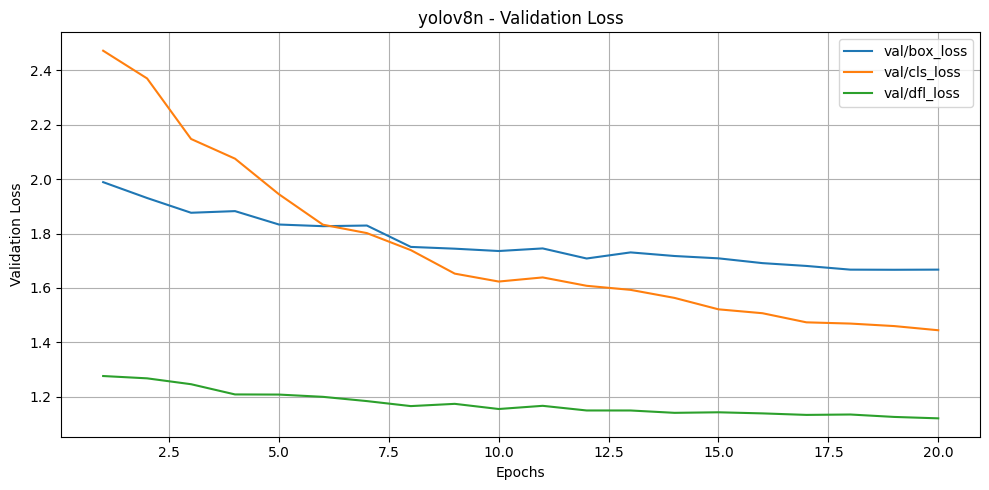

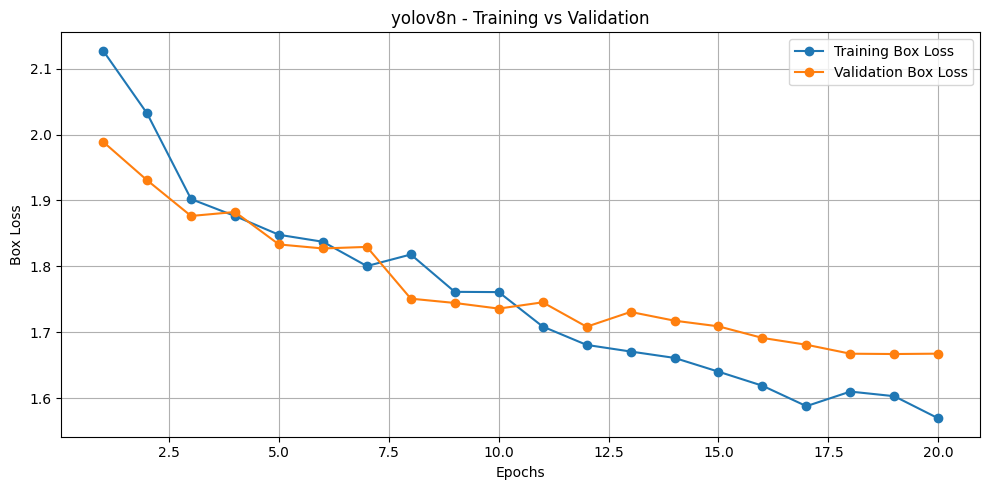

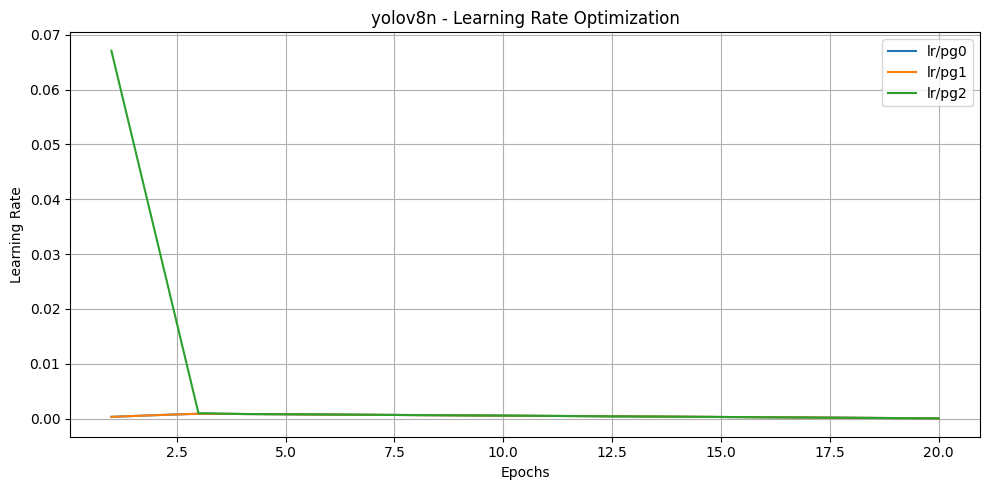

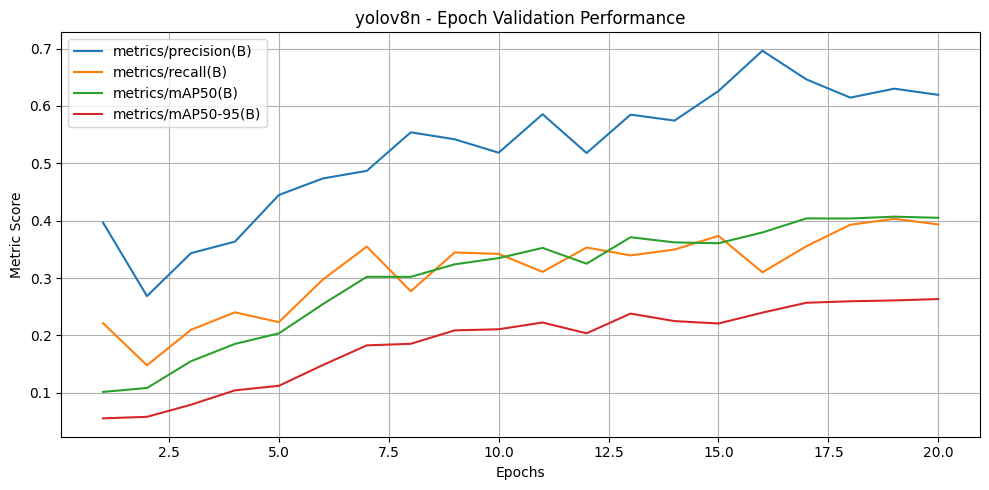

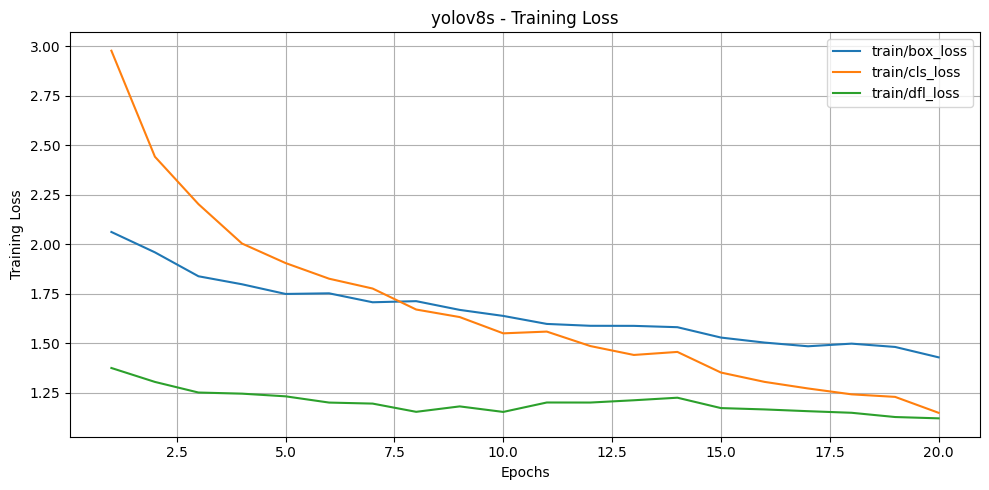

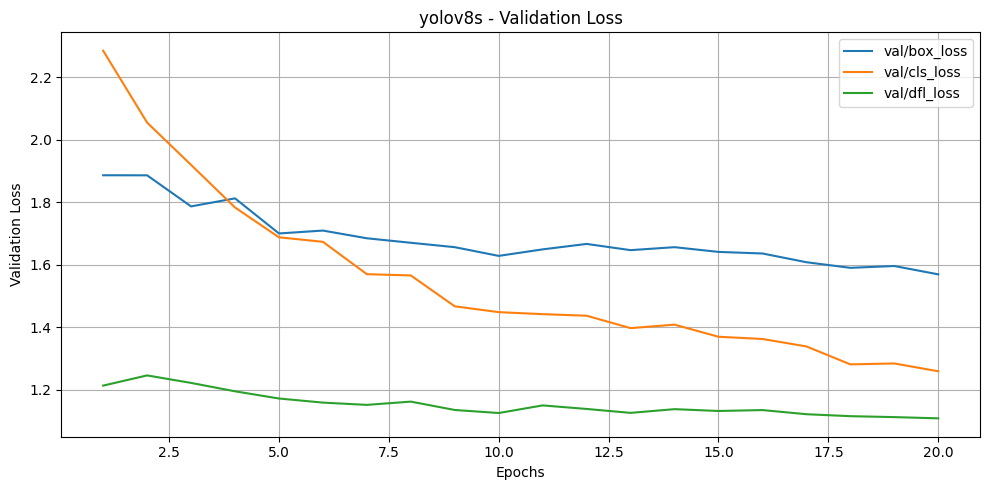

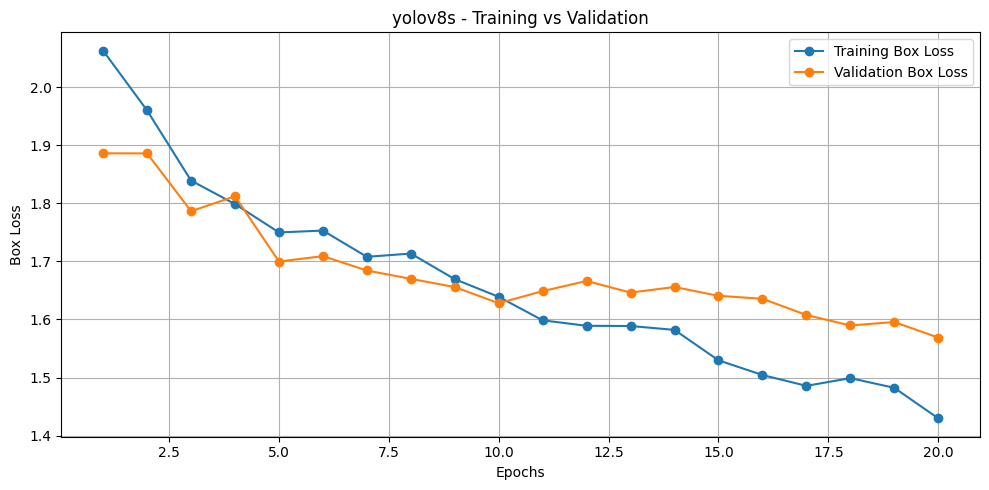

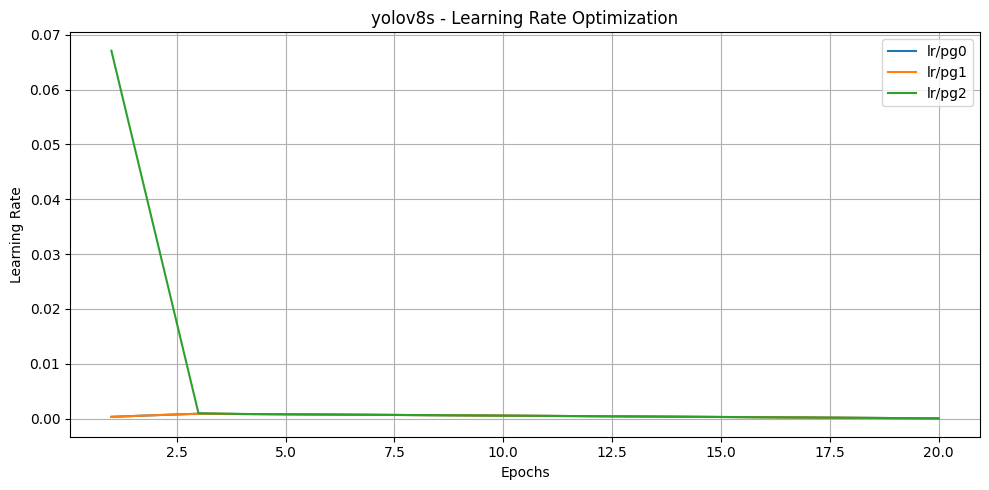

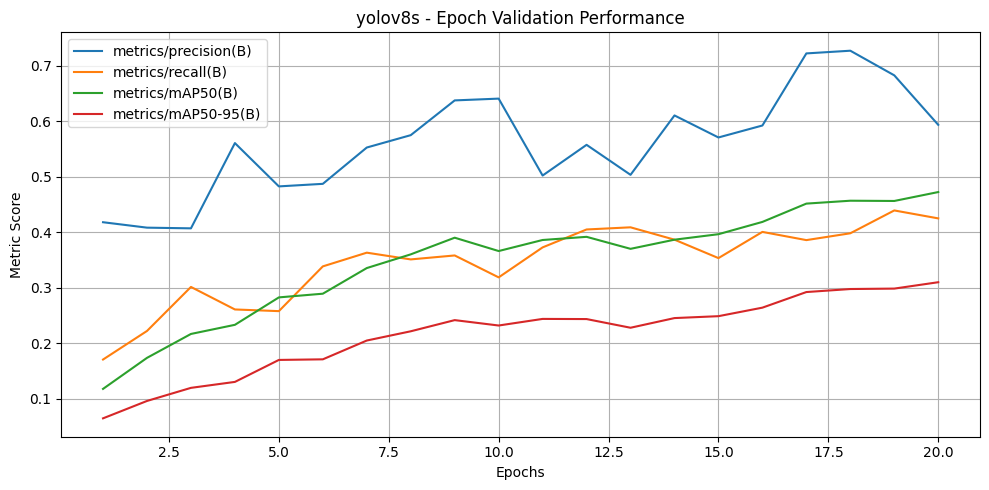

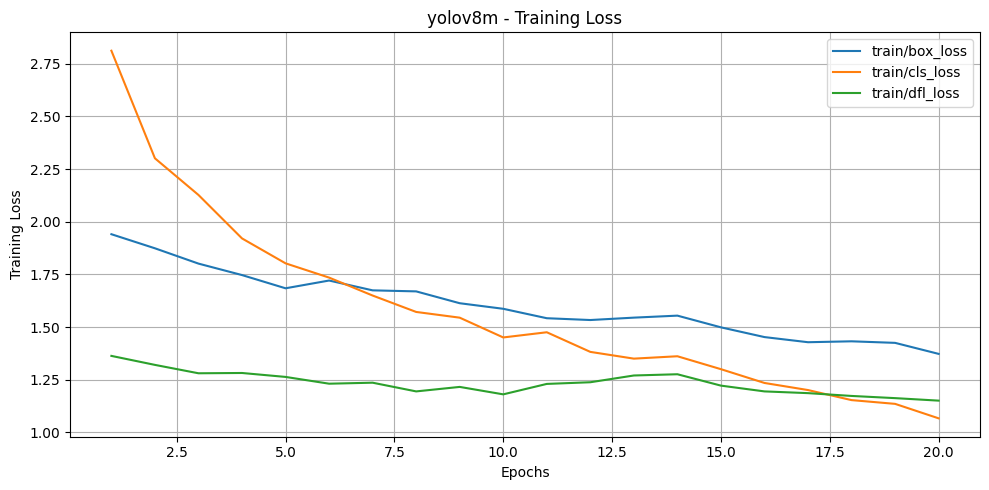

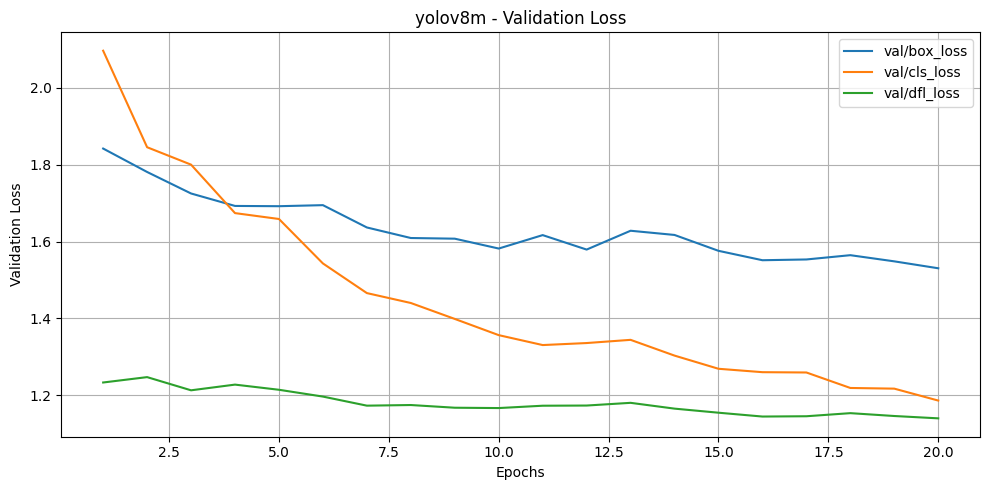

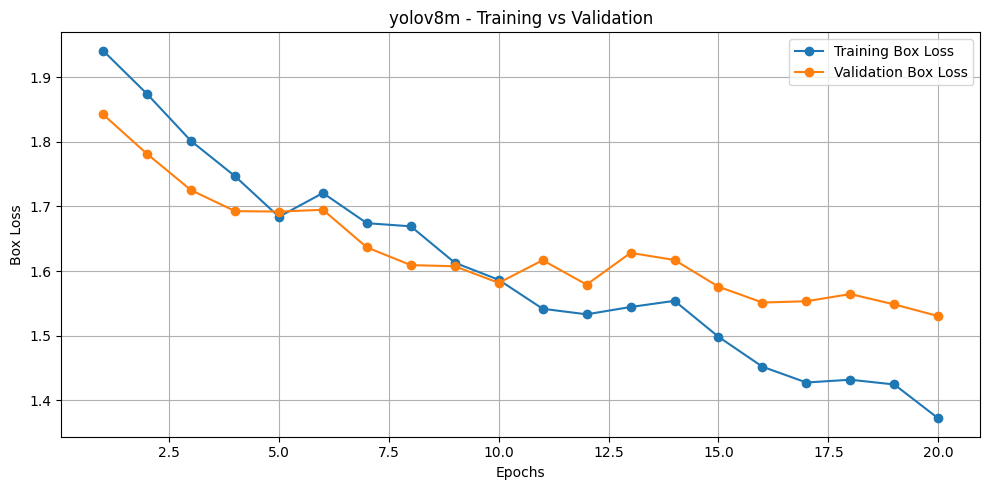

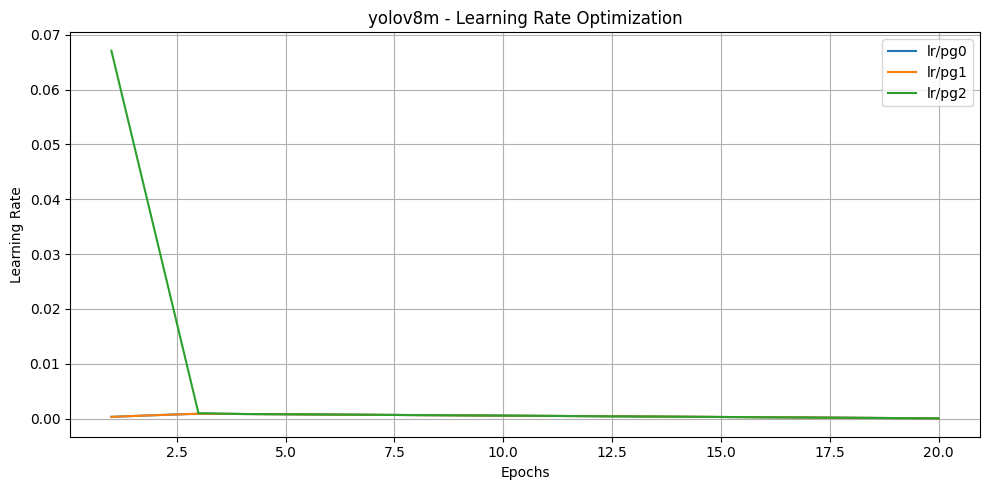

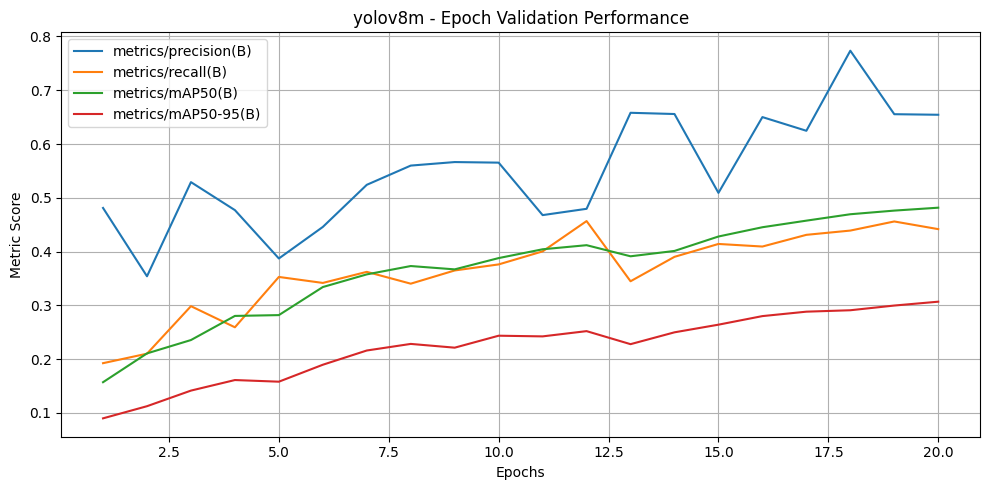

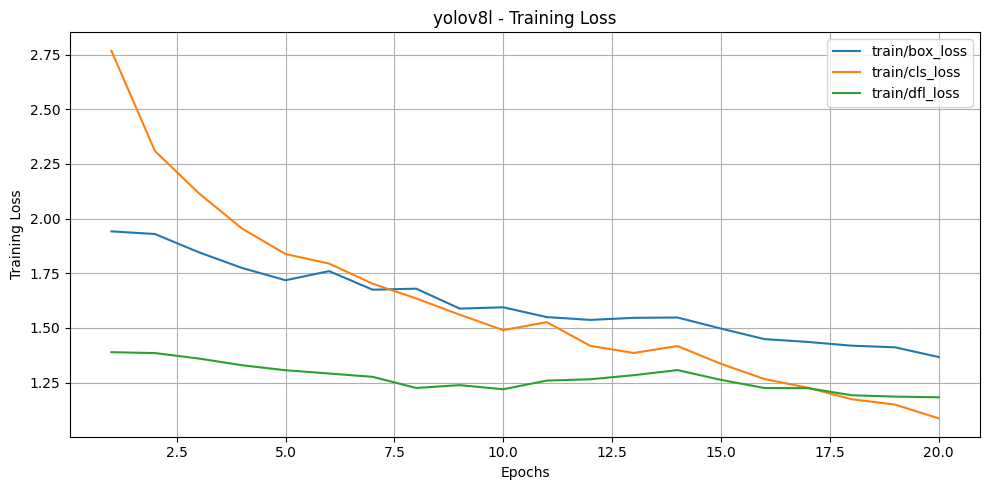

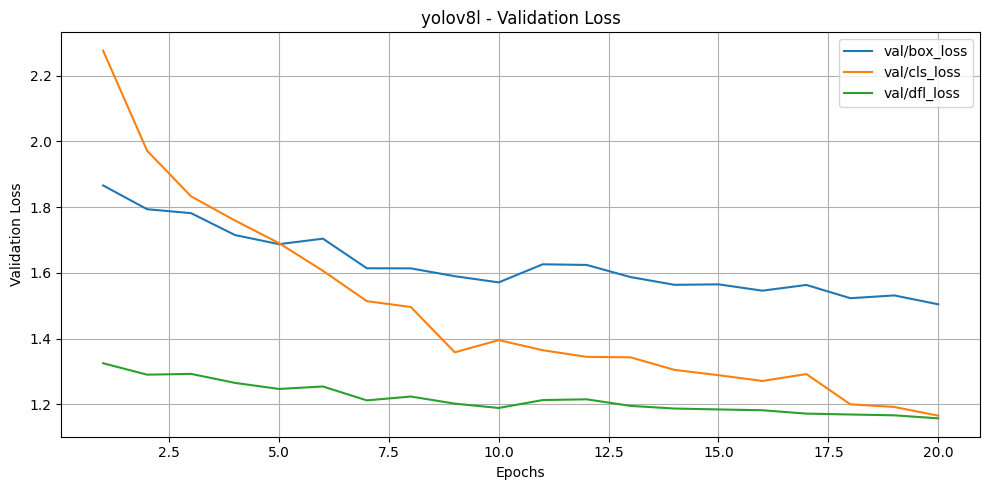

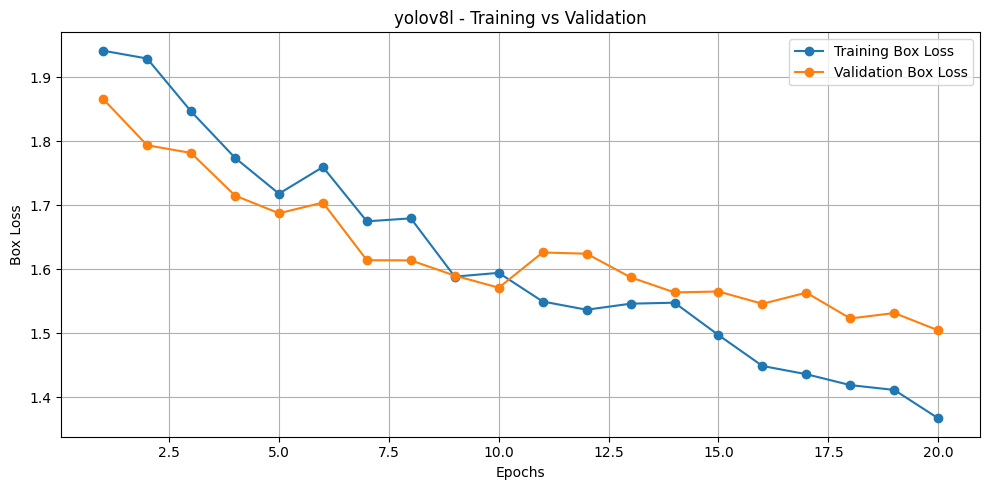

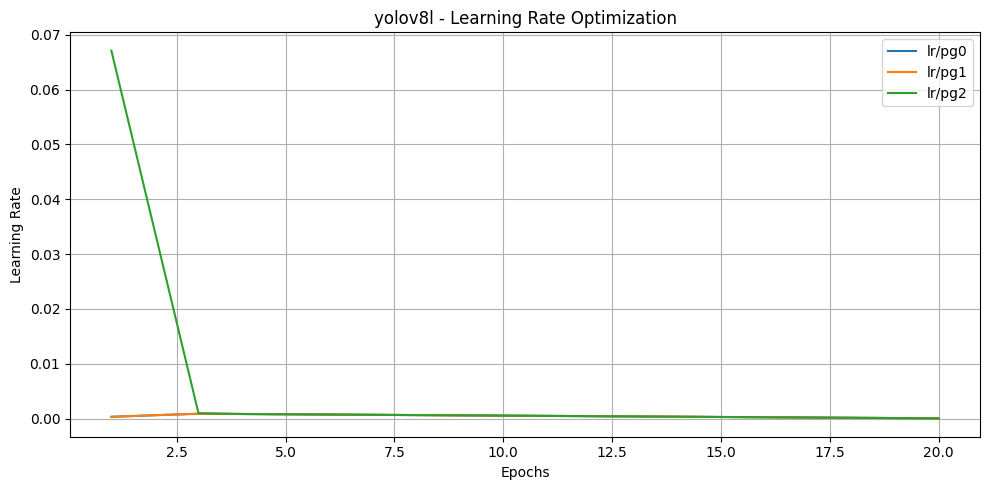

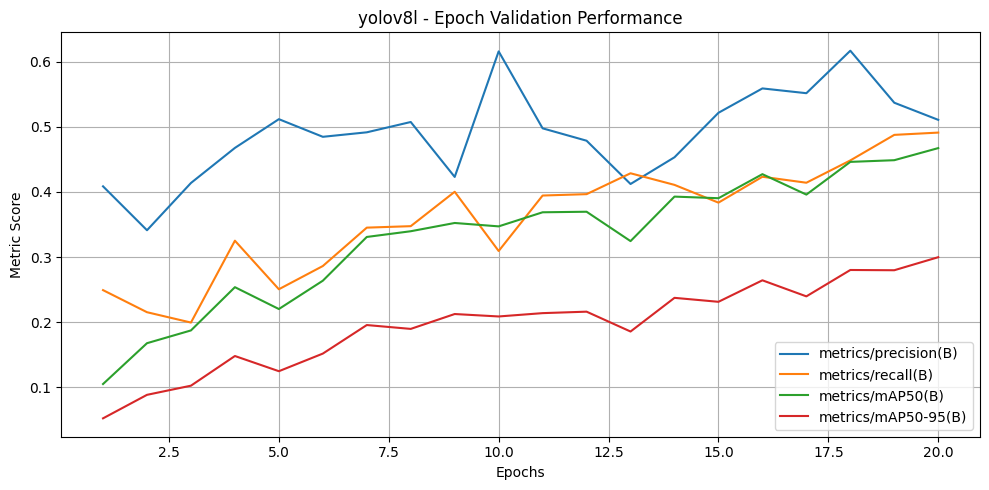

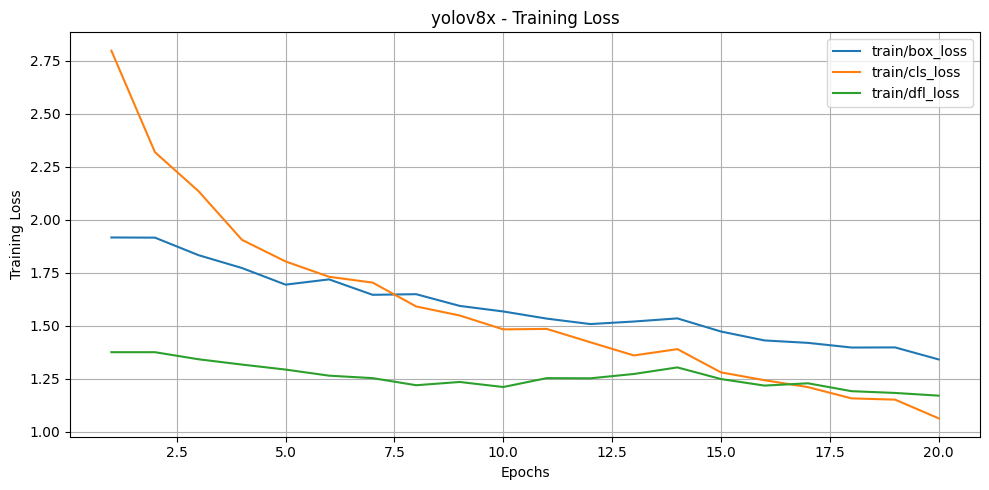

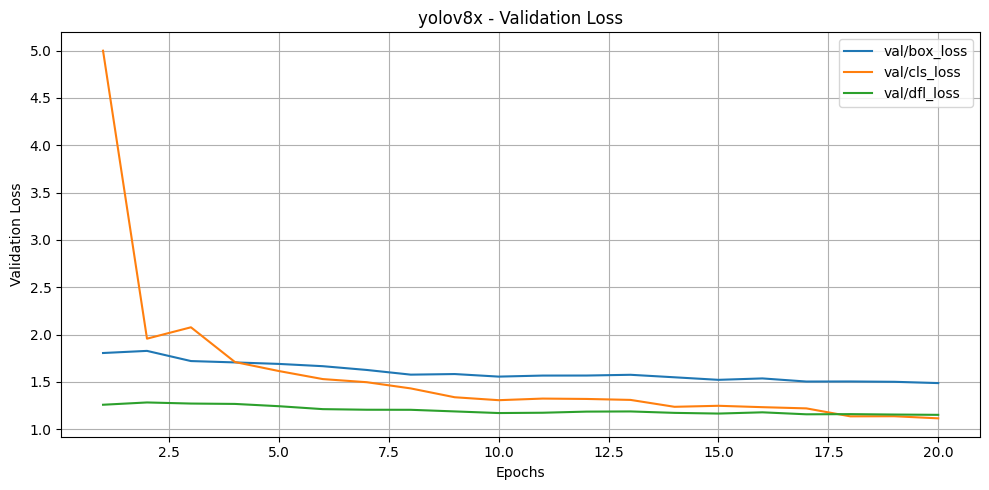

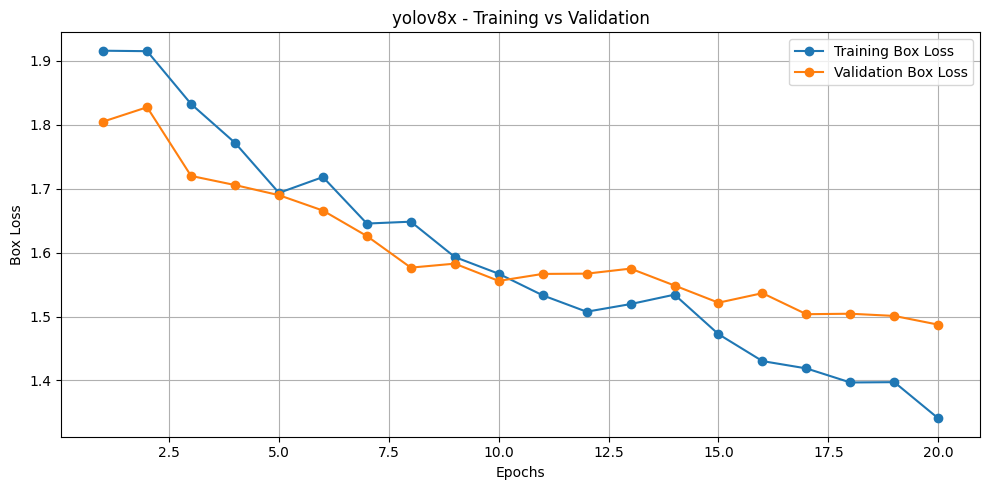

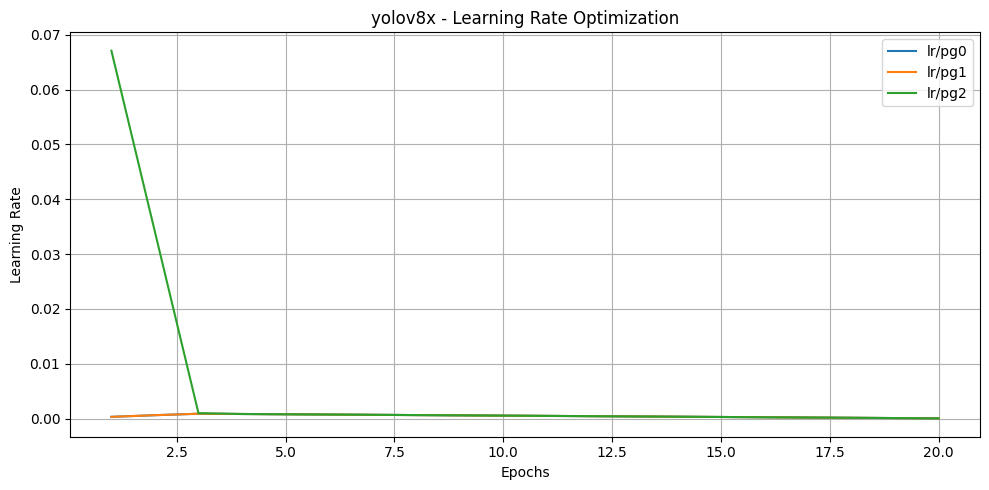

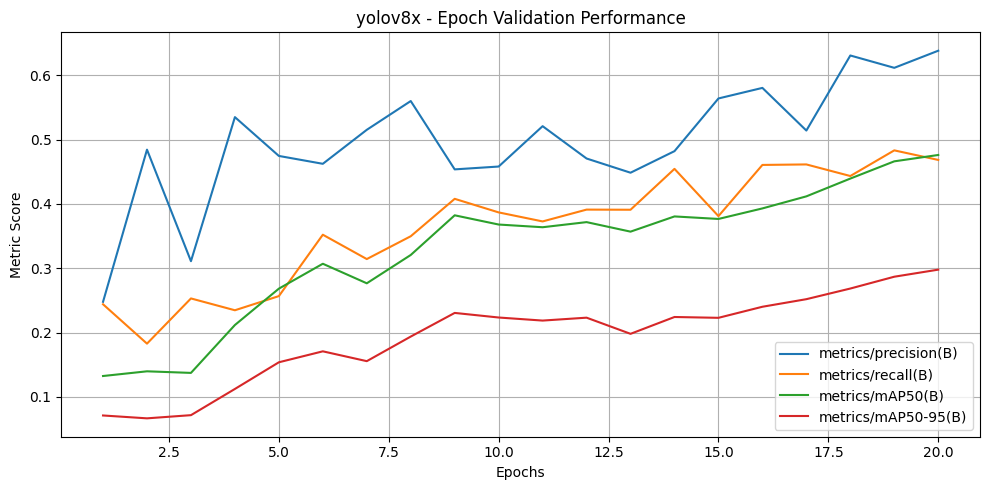

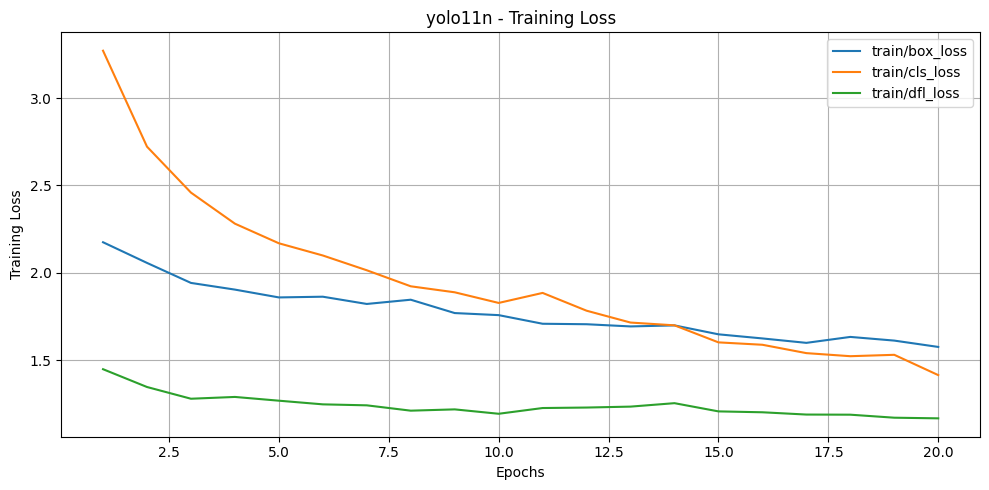

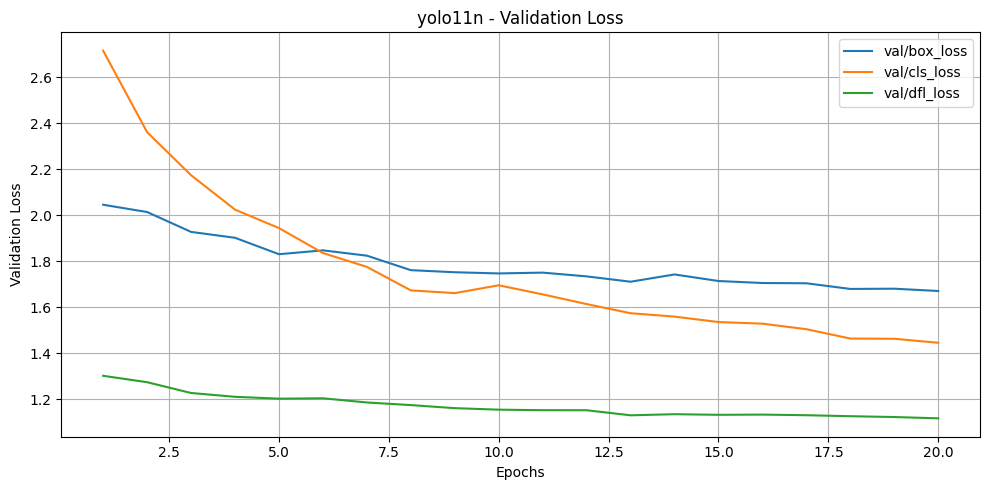

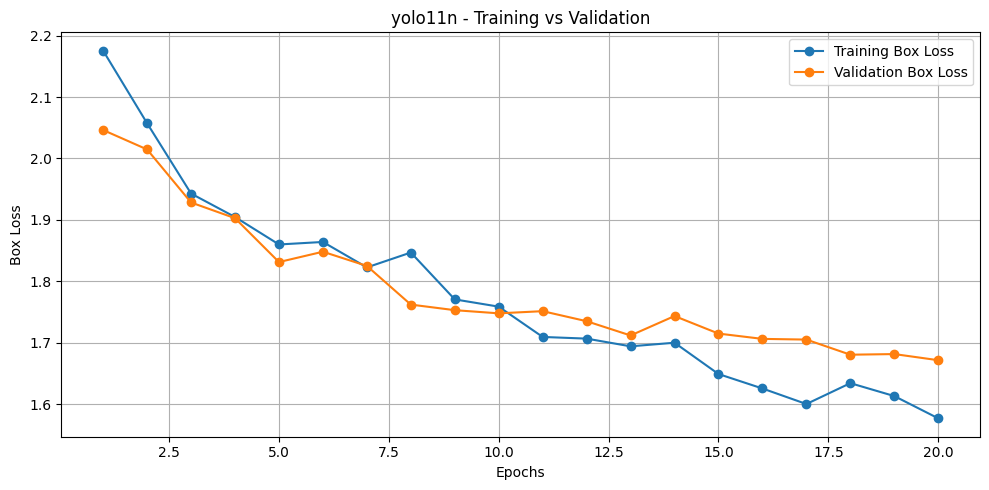

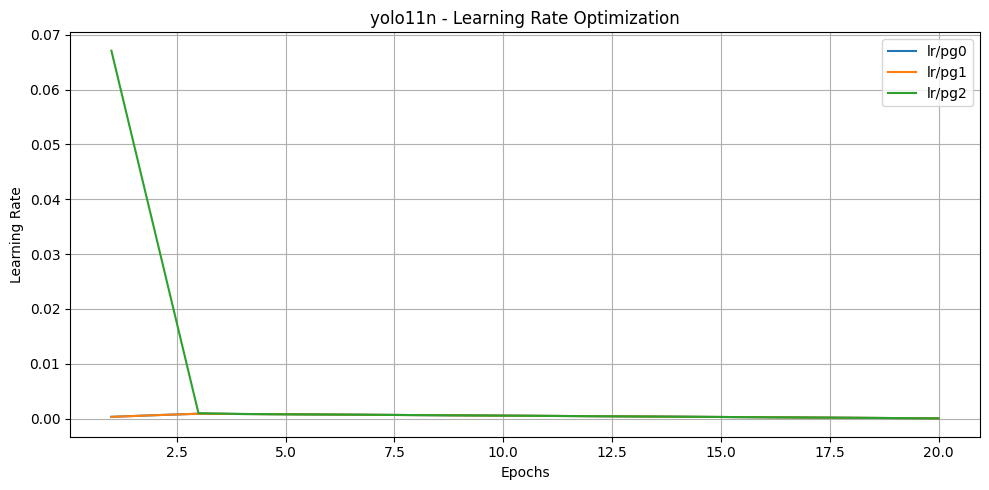

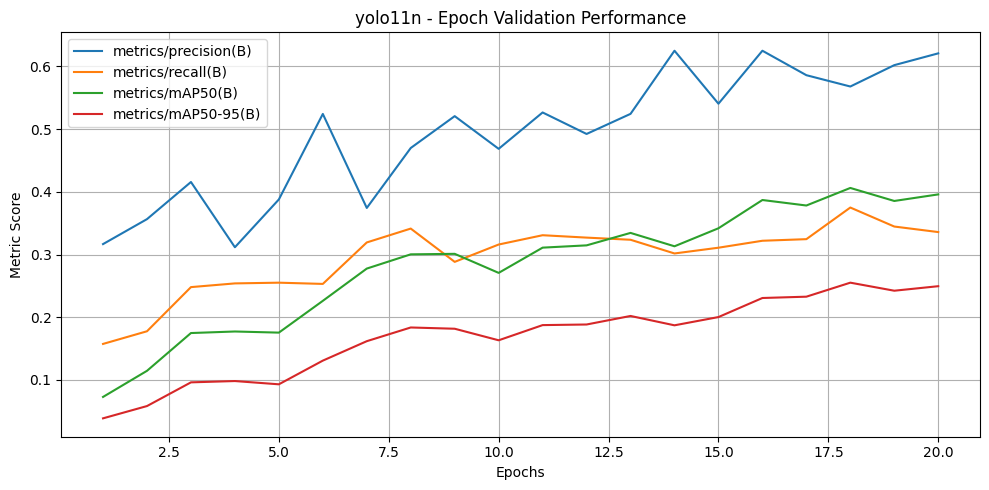

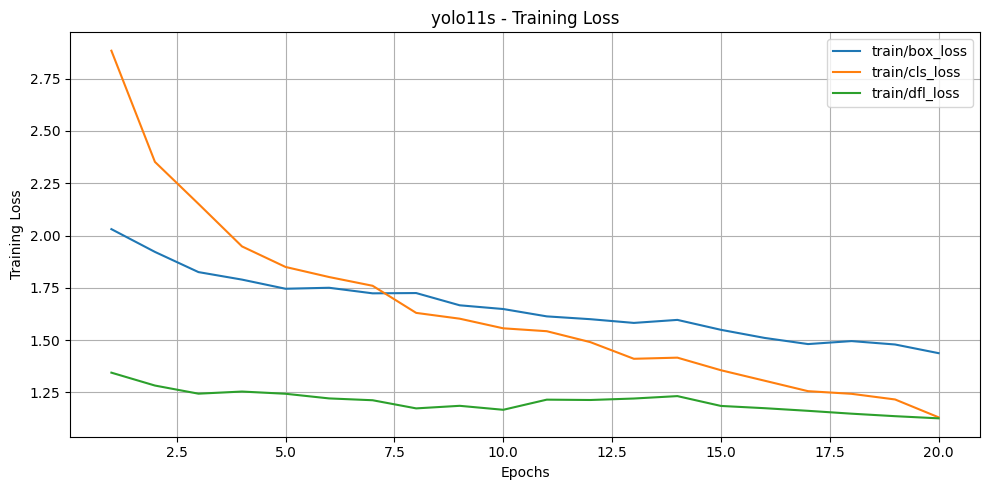

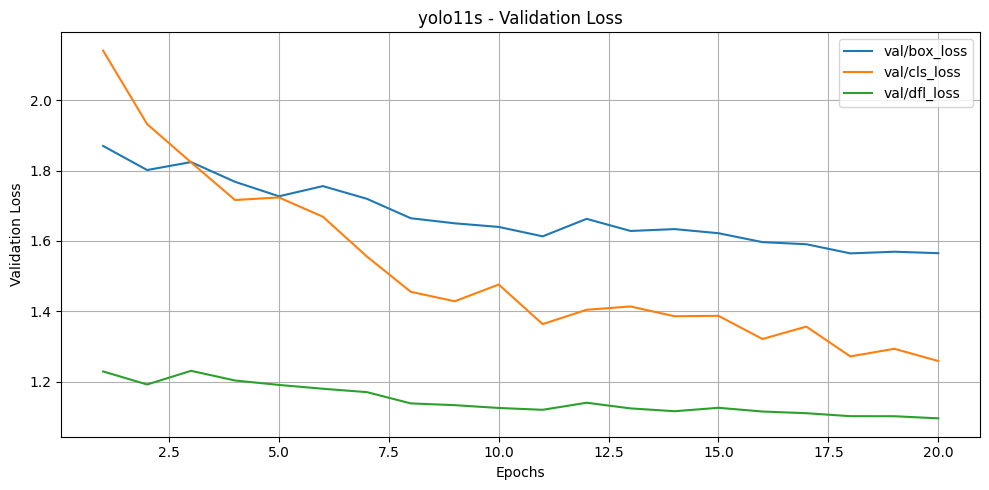

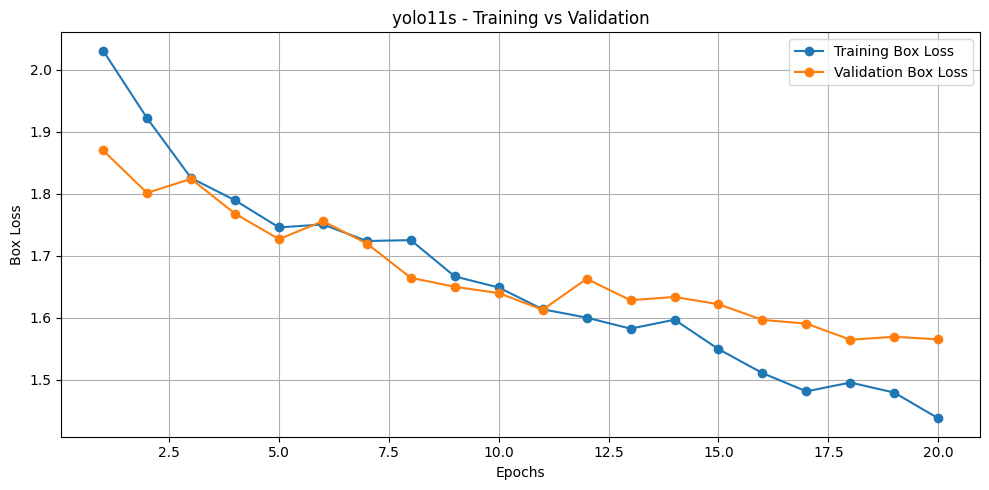

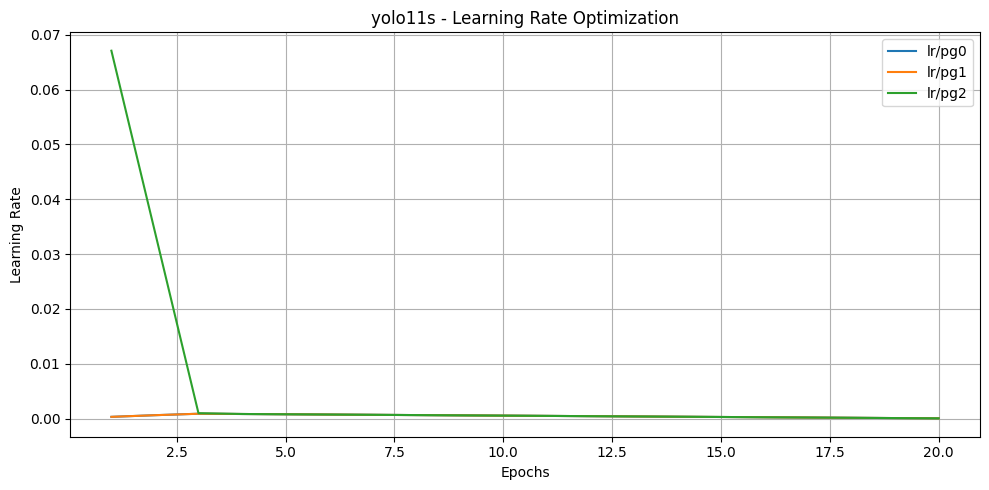

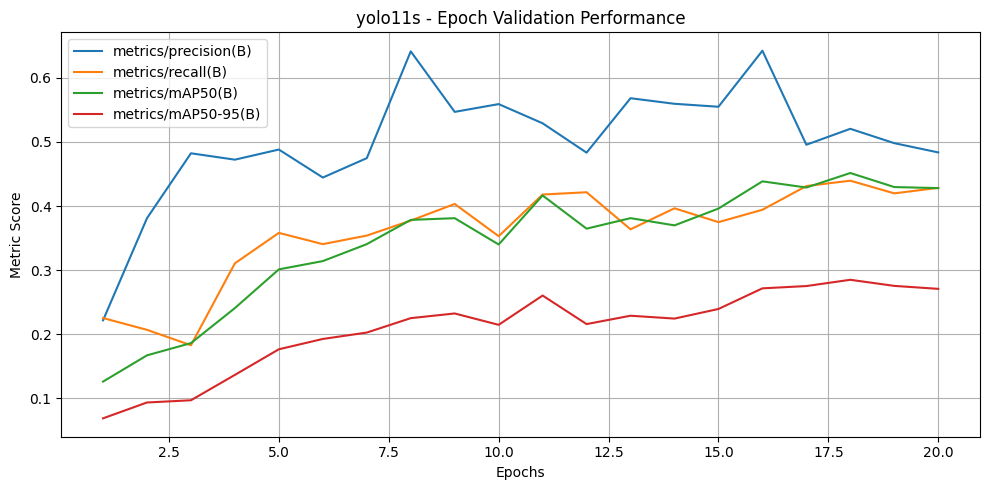


========== BEST MODEL SELECTION ==========
Best Model: yolov8m.pt
Precision: 0.6541210522488062
Recall: 0.44137665463985204
mAP50: 0.4836785287387778
mAP50-95: 0.3101926550191812


,Model,Precision,Recall,mAP50,mAP50-95
2,yolov8m.pt,0.654121,0.441377,0.483679,0.310193
4,yolov8x.pt,0.637732,0.466327,0.474452,0.298170
1,yolov8s.pt,0.591637,0.424224,0.471264,0.309783
3,yolov8l.pt,0.509304,0.490988,0.459880,0.295064
6,yolo11s.pt,0.525700,0.424186,0.452120,0.286062
5,yolo11n.pt,0.590873,0.365694,0.403836,0.254156
0,yolov8n.pt,0.622366,0.391382,0.402200,0.261830



========== CREATING FINAL ZIP ==========
Results saved: /content/PCB_Final_Results.zip

========== IMPLEMENTATION COMPLETED ==========
Models successfully trained: 7
Total models requested: 7
Output directory: /content/PCB_Results
ZIP file: /content/PCB_Final_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
# ================================================================
# PCB COMPONENT DETECTION - COMPLETE GOOGLE COLAB IMPLEMENTATION
# Dataset: aryanstein/pcb-component-detection-consolidated-dataset
# Seven YOLO Models + Analysis + Validation + Graphs + ZIP Export
# ================================================================

!pip install -q -U kagglehub ultralytics pyyaml seaborn tqdm

import os
import gc
import glob
import yaml
import shutil
import hashlib
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import kagglehub

from pathlib import Path
from PIL import Image
from collections import Counter
from tqdm.auto import tqdm
from ultralytics import YOLO
from IPython.display import display

warnings.filterwarnings("ignore")

# ===================== CONFIGURATION =====================

EPOCHS = 20
IMAGE_SIZE = 640
BATCH_SIZE = 2
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

OUTPUT_DIR = "/content/PCB_Results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

MODELS = [
    "yolov8n.pt",
    "yolov8s.pt",
    "yolov8m.pt",
    "yolov8l.pt",
    "yolov8x.pt",
    "yolo11n.pt",
    "yolo11s.pt"
]

# ===================== GPU CHECK =====================

print("\n========== GPU INFORMATION ==========")
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU not detected. Select Runtime > Change runtime type > T4 GPU."
    )

print("GPU:", torch.cuda.get_device_name(0))

# ===================== DATASET DOWNLOAD =====================

print("\n========== DOWNLOADING DATASET ==========")

DATASET_PATH = kagglehub.dataset_download(
    "aryanstein/pcb-component-detection-consolidated-dataset"
)

print("Dataset location:", DATASET_PATH)

# ===================== FIND YAML CONFIGURATION =====================

print("\n========== SEARCHING DATASET CONFIGURATION ==========")

yaml_files = []

for root, dirs, files in os.walk(DATASET_PATH):
    for filename in files:
        if filename.lower() in ["data.yaml", "dataset.yaml"]:
            yaml_files.append(os.path.join(root, filename))

if not yaml_files:
    raise FileNotFoundError(
        "No data.yaml found. This dataset needs YOLO annotations "
        "or conversion into YOLO format before training."
    )

valid_config = None

# Helper function to recursively find a folder in DATASET_PATH matching a certain name/pattern
def find_folder_by_name(target_name):
    for r, d, f in os.walk(DATASET_PATH):
        for directory in d:
            if directory.lower() == target_name.lower():
                # Ensure it contains subdirectories like images/labels, or images directly
                potential_path = Path(r) / directory
                if (potential_path / "images").exists() or any(potential_path.glob("*.jpg")) or any(potential_path.glob("*.png")):
                    return potential_path.resolve()
    return None

for yaml_file in yaml_files:
    try:
        with open(yaml_file, "r") as f:
            config = yaml.safe_load(f)

        if not isinstance(config, dict):
            continue

        if not all(k in config for k in ["train", "val", "names"]):
            continue

        base = Path(config.get("path", "."))
        if not base.is_absolute():
            base = (Path(yaml_file).parent / base).resolve()

        def resolve_split(split):
            p = Path(split)
            if p.is_absolute():
                return p.resolve()
            # Try relative to yaml directory
            yaml_rel = (Path(yaml_file).parent / p).resolve()
            if yaml_rel.exists():
                return yaml_rel
            # Try relative to resolved base path
            base_rel = (base / p).resolve()
            if base_rel.exists():
                return base_rel
            return None

        train_dir = resolve_split(config["train"])
        val_dir = resolve_split(config["val"])

        # Fallback search if standard resolution fails
        if train_dir is None or not train_dir.exists():
            found_train = find_folder_by_name("train")
            if found_train:
                train_dir = found_train / "images" if (found_train / "images").exists() else found_train

        if val_dir is None or not val_dir.exists():
            found_val = find_folder_by_name("valid") or find_folder_by_name("val")
            if found_val:
                val_dir = found_val / "images" if (found_val / "images").exists() else found_val

        if train_dir and val_dir and train_dir.exists() and val_dir.exists():
            valid_config = (yaml_file, config, train_dir, val_dir)
            break

    except Exception as e:
        print("Configuration skipped:", yaml_file, str(e))

if valid_config is None:
    raise RuntimeError(
        "No valid YOLO train/validation configuration found. "
        "Check the dataset folder and its annotations."
    )

yaml_file, config, train_dir, val_dir = valid_config

print("Selected YAML:", yaml_file)
print("Train directory:", train_dir)
print("Validation directory:", val_dir)

# ===================== NORMALIZE YAML PATHS =====================

names = config["names"]

if isinstance(names, dict):
    class_names = {
        int(k): str(v) for k, v in names.items()
    }
else:
    class_names = {
        i: str(v) for i, v in enumerate(names)
    }

if not class_names:
    raise ValueError("No classes found in YAML.")

if sorted(class_names) != list(range(len(class_names))):
    raise ValueError("Class IDs must be consecutive, starting from zero.")

normalized_config = dict(config)
# Define absolute root for ultralytics based on resolved splits parent directory
normalized_config["path"] = str(train_dir.parent.parent.resolve())
# Point train and val paths relative to this newly defined 'path' root
normalized_config["train"] = str(train_dir.relative_to(train_dir.parent.parent))
normalized_config["val"] = str(val_dir.relative_to(val_dir.parent.parent))
normalized_config["names"] = class_names
normalized_config["nc"] = len(class_names)

if config.get("test"):
    test_dir = Path(config["test"])
    if not test_dir.is_absolute():
        base = Path(config.get("path", "."))
        if not base.is_absolute():
            base = (Path(yaml_file).parent / base).resolve()
        test_dir = (base / test_dir).resolve()

    if not test_dir.exists():
        found_test = find_folder_by_name("test")
        if found_test:
            test_dir = found_test / "images" if (found_test / "images").exists() else found_test

    if test_dir.exists():
        normalized_config["test"] = str(test_dir.relative_to(train_dir.parent.parent))

NORMALIZED_YAML = "/content/pcb_fixed_data.yaml"

with open(NORMALIZED_YAML, "w") as f:
    yaml.safe_dump(normalized_config, f, sort_keys=False)

print("\nClasses:", class_names)
print("Number of classes:", len(class_names))

# ===================== IMAGE AND LABEL ANALYSIS =====================

print("\n========== INITIAL DATASET ANALYSIS ==========")

all_images = []

for root, dirs, files in os.walk(DATASET_PATH):
    for filename in files:
        if filename.lower().endswith(IMAGE_EXTENSIONS):
            all_images.append(os.path.join(root, filename))

print("Total images:", len(all_images))

if not all_images:
    raise RuntimeError("No image files found in the dataset.")

# Locate annotation directories
label_dirs = []

for root, dirs, files in os.walk(DATASET_PATH):
    if os.path.basename(root).lower() == "labels":
        label_dirs.append(root)

all_labels = []

for folder in label_dirs:
    all_labels.extend(glob.glob(os.path.join(folder, "*.txt")))

print("Label directories:", len(label_dirs))
print("Total label files:", len(all_labels))

if not all_labels:
    raise RuntimeError(
        "No YOLO TXT annotations found. "
        "The dataset may use XML, JSON or another format. "
        "Convert annotations to YOLO format before training."
    )

# ===================== IMAGE FORMAT ANALYSIS =====================

format_counts = Counter(
    os.path.splitext(x)[1].lower() for x in all_images
)

print("\nImage formats:", dict(format_counts))

plt.figure(figsize=(9, 5))
plt.bar(format_counts.keys(), format_counts.values())
plt.title("PCB Image Format Distribution")
plt.xlabel("Image Format")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.savefig(OUTPUT_DIR + "/image_formats.png")
plt.show()

# ===================== CLASS DISTRIBUTION =====================

class_counts = Counter()
valid_label_lines = 0
invalid_label_lines = 0

for label_file in tqdm(all_labels, desc="Analyzing annotations"):
    try:
        with open(label_file, "r") as f:
            for line in f:
                parts = line.strip().split()

                if len(parts) != 5:
                    continue

                try:
                    class_id = int(float(parts[0]))
                    values = [float(x) for x in parts[1:]]

                    if (
                        class_id in class_names
                        and all(np.isfinite(values))
                        and all(0 <= x <= 1 for x in values)
                        and values[2] > 0
                        and values[3] > 0
                    ):
                        class_counts[class_id] += 1
                        valid_label_lines += 1
                    else:
                        invalid_label_lines += 1

                except Exception:
                    invalid_label_lines += 1

    except Exception:
        invalid_label_lines += 1

class_df = pd.DataFrame([
    {
        "Class ID": i,
        "Class": class_names[i],
        "Object Count": class_counts[i]
    }
    for i in class_names
])

print("\n========== CLASS DISTRIBUTION ==========")
display(class_df)

print("Valid annotations:", valid_label_lines)
print("Invalid annotations:", invalid_label_lines)

if valid_label_lines == 0:
    raise RuntimeError("No valid YOLO bounding-box annotations found.")

plt.figure(figsize=(15, 6))
sns.barplot(data=class_df, x="Class", y="Object Count")
plt.title("PCB Component Class Distribution")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR + "/class_distribution.png")
plt.show()

# ===================== IMAGE SIZE ANALYSIS =====================

print("\n========== IMAGE RESOLUTION ANALYSIS ==========")

resolution_counts = Counter()
image_sizes = []

for image_path in tqdm(all_images, desc="Checking image sizes"):
    try:
        with Image.open(image_path) as img:
            resolution_counts[img.size] += 1
            image_sizes.append(img.size)
    except Exception:
        pass

resolution_df = pd.DataFrame(
    [
        {"Resolution": str(k), "Count": v}
        for k, v in resolution_counts.most_common(15)
    ]
)

display(resolution_df)

plt.figure(figsize=(12, 5))
sns.barplot(data=resolution_df, x="Resolution", y="Count")
plt.title("Top PCB Image Resolutions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(OUTPUT_DIR + "/resolution_comparison.png")
plt.show()

# ===================== DUPLICATE DETECTION =====================

print("\n========== DUPLICATE IMAGE ANALYSIS ==========")

hashes = {}

for image_path in tqdm(all_images, desc="Checking duplicates"):
    try:
        sha = hashlib.sha256()

        with open(image_path, "rb") as f:
            for chunk in iter(lambda: f.read(1024 * 1024), b""):
                sha.update(chunk)

        digest = sha.hexdigest()
        hashes.setdefault(digest, []).append(image_path)

    except Exception:
        pass

duplicate_groups = [
    group for group in hashes.values() if len(group) > 1
]

duplicate_count = sum(
    len(group) - 1 for group in duplicate_groups
)

print("Unique image hashes:", len(hashes))
print("Duplicate groups:", len(duplicate_groups))
print("Extra duplicate images:", duplicate_count)

# ===================== SAMPLE IMAGE DISPLAY =====================

print("\n========== SAMPLE PCB IMAGES ==========")

samples = random.sample(
    all_images,
    min(12, len(all_images))
)

plt.figure(figsize=(15, 10))

for i, image_path in enumerate(samples):
    try:
        img = Image.open(image_path).convert("RGB")

        plt.subplot(3, 4, i + 1)
        plt.imshow(img)
        plt.title(os.path.basename(image_path)[:25])
        plt.axis("off")
    except Exception:
        pass

plt.suptitle("Sample PCB Images")
plt.tight_layout()
plt.savefig(OUTPUT_DIR + "/sample_images.png")
plt.show()

# ===================== VERIFY YOLO SPLITS =====================

def count_images(folder):
    return sum(
        1 for x in folder.rglob("*")
        if x.is_file() and x.suffix.lower() in IMAGE_EXTENSIONS
    )

train_images = count_images(train_dir)
val_images = count_images(val_dir)

print("\n========== TRAIN / VALIDATION DATA ==========")
print("Training images:", train_images)
print("Validation images:", val_images)

if train_images == 0 or val_images == 0:
    raise RuntimeError("Training or validation images are missing.")

# Verify annotation directories
def get_label_directory(image_directory):
    # Fix string operations to be fully safe with path segments
    path_str = str(image_directory)
    if "images" in path_str:
        return Path(path_str.replace("images", "labels"))
    return Path(path_str).parent / "labels"

train_label_dir = get_label_directory(train_dir)
val_label_dir = get_label_directory(val_dir)

print("Train labels:", train_label_dir)
print("Validation labels:", val_label_dir)

if not train_label_dir.exists() or not val_label_dir.exists():
    raise RuntimeError(
        "Matching YOLO label folders are missing for train or validation."
    )

train_label_count = len(list(train_label_dir.rglob("*.txt")))
val_label_count = len(list(val_label_dir.rglob("*.txt")))

print("Training label files:", train_label_count)
print("Validation label files:", val_label_count)

if train_label_count == 0 or val_label_count == 0:
    raise RuntimeError(
        "Train or validation labels are empty. "
        "Check image-label filename matching."
    )

# ===================== SEVEN MODEL TRAINING =====================

print("\n========== STARTING SEVEN MODEL TRAINING ==========")

model_results = []

for index, model_name in enumerate(MODELS, start=1):

    run_name = model_name.replace(".pt", "")

    print("\n")
    print("=" * 65)
    print(f"MODEL {index}/7: {model_name}")
    print("=" * 65)

    try:

        model = YOLO(model_name)

        model.train(
            data=NORMALIZED_YAML,
            epochs=EPOCHS,
            imgsz=IMAGE_SIZE,
            batch=BATCH_SIZE,
            device=0,
            workers=2,
            patience=8,
            optimizer="AdamW",
            lr0=0.001,
            project=OUTPUT_DIR,
            name=run_name,
            exist_ok=True,
            pretrained=True,
            plots=True,
            save=True,
            cache=False,
            seed=SEED,
            verbose=True
        )

        best_weights = os.path.join(
            OUTPUT_DIR,
            run_name,
            "weights",
            "best.pt"
        )

        if not os.path.exists(best_weights):
            print("Best model weights not found. Skipping validation.")
            continue

        print("Best weights:", best_weights)

        # ================= VALIDATION =================

        best_model = YOLO(best_weights)

        metrics = best_model.val(
            data=NORMALIZED_YAML,
            split="val",
            imgsz=IMAGE_SIZE,
            batch=BATCH_SIZE,
            device=0,
            plots=True,
            project=OUTPUT_DIR,
            name=run_name + "_validation",
            exist_ok=True
        )

        result = {
            "Model": model_name,
            "Precision": float(metrics.box.mp),
            "Recall": float(metrics.box.mr),
            "mAP50": float(metrics.box.map50),
            "mAP50-95": float(metrics.box.map)
        }

        model_results.append(result)

        print("\nMODEL VALIDATION RESULTS")
        print(pd.Series(result))

        del model
        del best_model
        gc.collect()
        torch.cuda.empty_cache()

    except Exception as e:

        print("\nMODEL FAILED:", model_name)
        print("Error:", str(e))

        gc.collect()
        torch.cuda.empty_cache()

# ===================== SAVE RESULTS =====================

if not model_results:
    raise RuntimeError(
        "All models failed. Check the first training error above."
    )

results_df = pd.DataFrame(model_results)

results_df.to_csv(
    OUTPUT_DIR + "/seven_model_results.csv",
    index=False
)

print("\n========== SEVEN MODEL RESULTS ==========")
display(results_df)

# ===================== ACCURACY / MAP GRAPH =====================

plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="mAP50"
)

plt.title("Seven Model Accuracy Comparison (mAP50)")
plt.xlabel("Models")
plt.ylabel("mAP50")
plt.ylim(0, 1)
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(OUTPUT_DIR + "/accuracy_comparison.png")
plt.show()

# ===================== SEVEN MODEL VALIDATION =====================

for metric in ["Precision", "Recall", "mAP50", "mAP50-95"]:

    plt.figure(figsize=(12, 6))

    sns.barplot(
        data=results_df,
        x="Model",
        y=metric
    )

    plt.title("Seven Model Validation - " + metric)
    plt.ylabel(metric)
    plt.xticks(rotation=30)
    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR + "/" + metric + "_validation.png"
    )

    plt.show()

# ===================== COMBINED VALIDATION GRAPH =====================

plt.figure(figsize=(12, 6))

for metric in ["Precision", "Recall", "mAP50", "mAP50-95"]:
    plt.plot(
        results_df["Model"],
        results_df[metric],
        marker="o",
        label=metric
    )

plt.title("Seven Model Validation Comparison")
plt.xlabel("Models")
plt.ylabel("Validation Score")
plt.legend()
plt.grid(True)
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(OUTPUT_DIR + "/validation_graph.png")
plt.show()

# ===================== TRAINING / LOSS / OPTIMIZATION GRAPHS =====================

for model_name in MODELS:

    run_name = model_name.replace(".pt", "")

    csv_file = os.path.join(
        OUTPUT_DIR,
        run_name,
        "results.csv"
    )

    if not os.path.exists(csv_file):
        print("Training history unavailable:", run_name)
        continue

    df = pd.read_csv(csv_file)
    df.columns = df.columns.str.strip()

    epochs = np.arange(1, len(df) + 1)

    # -------- TRAINING LOSS --------

    train_cols = [
        c for c in df.columns
        if c.startswith("train/") and "loss" in c
    ]

    if train_cols:

        plt.figure(figsize=(10, 5))

        for col in train_cols:
            plt.plot(epochs, df[col], label=col)

        plt.title(run_name + " - Training Loss")
        plt.xlabel("Epochs")
        plt.ylabel("Training Loss")
        plt.legend()
        plt.grid(True)
        plt.tight_layout()

        plt.savefig(
            os.path.join(
                OUTPUT_DIR,
                run_name + "_training_loss.png"
            )
        )

        plt.show()

    # -------- VALIDATION LOSS --------

    val_cols = [
        c for c in df.columns
        if c.startswith("val/") and "loss" in c
    ]

    if val_cols:

        plt.figure(figsize=(10, 5))

        for col in val_cols:
            plt.plot(epochs, df[col], label=col)

        plt.title(run_name + " - Validation Loss")
        plt.xlabel("Epochs")
        plt.ylabel("Validation Loss")
        plt.legend()
        plt.grid(True)
        plt.tight_layout()

        plt.savefig(
            os.path.join(
                OUTPUT_DIR,
                run_name + "_validation_loss.png"
            )
        )

        plt.show()

    # -------- TRAINING VS VALIDATION --------

    train_box = "train/box_loss"
    val_box = "val/box_loss"

    if train_box in df.columns and val_box in df.columns:

        plt.figure(figsize=(10, 5))

        plt.plot(
            epochs,
            df[train_box],
            label="Training Box Loss",
            marker="o"
        )

        plt.plot(
            epochs,
            df[val_box],
            label="Validation Box Loss",
            marker="o"
        )

        plt.title(run_name + " - Training vs Validation")
        plt.xlabel("Epochs")
        plt.ylabel("Box Loss")
        plt.legend()
        plt.grid(True)
        plt.tight_layout()

        plt.savefig(
            os.path.join(
                OUTPUT_DIR,
                run_name + "_training_validation.png"
            )
        )

        plt.show()

    # -------- OPTIMIZATION / LEARNING RATE --------

    lr_cols = [
        c for c in df.columns if c.startswith("lr/")
    ]

    if lr_cols:

        plt.figure(figsize=(10, 5))

        for col in lr_cols:
            plt.plot(epochs, df[col], label=col)

        plt.title(run_name + " - Learning Rate Optimization")
        plt.xlabel("Epochs")
        plt.ylabel("Learning Rate")
        plt.legend()
        plt.grid(True)
        plt.tight_layout()

        plt.savefig(
            os.path.join(
                OUTPUT_DIR,
                run_name + "_optimization.png"
            )
        )

        plt.show()

    # -------- EPOCH VALIDATION METRICS --------

    metric_cols = [
        c for c in df.columns
        if c.startswith("metrics/")
    ]

    if metric_cols:

        plt.figure(figsize=(10, 5))

        for col in metric_cols:
            plt.plot(epochs, df[col], label=col)

        plt.title(run_name + " - Epoch Validation Performance")
        plt.xlabel("Epochs")
        plt.ylabel("Metric Score")
        plt.legend()
        plt.grid(True)
        plt.tight_layout()

        plt.savefig(
            os.path.join(
                OUTPUT_DIR,
                run_name + "_epoch_validation.png"
            )
        )

        plt.show()

# ===================== BEST MODEL =====================

print("\n========== BEST MODEL SELECTION ==========")

results_df = pd.DataFrame(model_results)

best_row = results_df.loc[results_df["mAP50"].idxmax()]

print("Best Model:", best_row["Model"])
print("Precision:", best_row["Precision"])
print("Recall:", best_row["Recall"])
print("mAP50:", best_row["mAP50"])
print("mAP50-95:", best_row["mAP50-95"])

results_df.sort_values(
    by="mAP50",
    ascending=False,
    inplace=True
)

display(results_df)

# ===================== SAVE FINAL CSV =====================

results_df.to_csv(
    OUTPUT_DIR + "/final_model_comparison.csv",
    index=False
)

# ===================== ZIP ALL RESULTS =====================

print("\n========== CREATING FINAL ZIP ==========")

ZIP_PATH = shutil.make_archive(
    "/content/PCB_Final_Results",
    "zip",
    OUTPUT_DIR
)

print("Results saved:", ZIP_PATH)

print("\n========== IMPLEMENTATION COMPLETED ==========")
print("Models successfully trained:", len(model_results))
print("Total models requested:", len(MODELS))
print("Output directory:", OUTPUT_DIR)
print("ZIP file:", ZIP_PATH)

# ===================== DOWNLOAD RESULTS =====================

from google.colab import files

files.download(ZIP_PATH)